In [1]:
from plot_eval_logs.parse_eval_logs import EvalRun
from pathlib import Path
import numpy as np


def refusal_rate_decomp(padding2evals: dict[int, EvalRun]):# -> tuple[dict[str, dict[Any, Any]], dict[Any, Any]]:
    refused_msgs_lens = {}
    for pad_len, evals in padding2evals.items():
        harm_logs = evals["harm"]
        refusal_rate_msg_lens = []
        for s in harm_logs._samples:
            if s.score.value["refusal"] == 1.0:
                refusal_rate_msg_lens.append(len(s.messages[2:]))
        refused_msgs_lens[pad_len] = [ r == 1 for r in refusal_rate_msg_lens]
    return refused_msgs_lens 

In [2]:
from typing import Any


LOG_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/") 
padding2evals: dict[int, Any] = {
    0: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt/2025-08-14T00-06-28+03-00_gpt-4.1-nano-rs-3-no-pad-hint-detprompt-testdefault-benign-test-public_EzPKGPiFRryvQPuTye3rLN.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt/2025-08-16T12-47-13+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_Pr3wK7wx3ufD4BGvs6MiLw.eval")
    },
    1000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/1000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-14T16-39-01+03-00_gpt-4.1-nano-rs-3-1k-pad-hint-detprompt-testdefault-benign-test-public_XhNMmXz6HidmW5TRpDqHAx.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/1000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-16T13-33-06+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_NaYVKuz4bqxs7rSCKNcrg2.eval")
    },
    5000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/5000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-15T21-28-03+03-00_gpt-4.1-nano-rs-3-5000-around-rand-pad-hint-detprompt-testdefault-benign-test-public_3W95QKUgUzu4otmmMGwACq.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/5000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-16T19-40-23+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_jDNHAmpSEE4Yy9oKsmLKPr.eval")
    },
    10000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/10000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-14T14-56-16+03-00_gpt-4.1-nano-rs-3-10k-pad-hint-detprompt-testdefault-benign-test-public_N23X9M9Gz6eAuMby5ToPif.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/10000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-16T21-17-45+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_XpN5AQka4iHzvQ9Bnxk4RW.eval")
    },
    100000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/100000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T18-25-23+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-benign-test-public_fcZMkXLwxLJErYcDVcL8xY.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/100000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-27T14-48-07+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_7L48iAUuboNXaRBnkdjzi2.eval")
    },
    200000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/200000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T22-30-01+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-benign-test-public_YLn2xUD7AbmWgHRt82jVzu.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/200000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-27T13-51-24+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_2sEdVXDxA8oafWSReZLLZ9.eval")
    },
    800000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/800000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T21-08-25+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-benign-test-public_bXmuDeFvc5D6LDGWWDaxBi.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/800000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T23-27-42+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_EfK2UMbEdfpa4TZvrvvrrb.eval")
    },
} 


In [4]:
msgs_len = refusal_rate_decomp(padding2evals)

In [5]:
import matplotlib.pyplot as plt
from collections.abc import Mapping

def plot_stacked_bool_bars(
    data: Mapping,

    normalize: bool = False,
    sort_x: bool = False,
    numeric_sort: bool = True,
    rotation: int = 0,
    annotate: bool = False,
    ax=None,
):

    if not isinstance(data, Mapping):
        raise TypeError("`data` must be a mapping of key -> list[bool].")

    # Order keys
    keys = list(data.keys())
    if sort_x:
        if numeric_sort:
            try:
                keys = sorted(keys, key=float)
            except Exception:
                keys = sorted(keys, key=str)
        else:
            keys = sorted(keys, key=str)

    # Count True/False per key (count only literal True)
    true_counts, false_counts = [], []
    for k in keys:
        vals = list(data[k])
        t = sum(v is True for v in vals)
        f = len(vals) - t
        true_counts.append(t)
        false_counts.append(f)

    totals = [t + f for t, f in zip(true_counts, false_counts)]
    if normalize:
        denom = [max(1, n) for n in totals]  # avoid div-by-zero
        true_plot = [t / d for t, d in zip(true_counts, denom)]
        false_plot = [f / d for f, d in zip(false_counts, denom)]
        ylabel = "Refusals Fraction"
        fmt = "{:.2f}"
    else:
        true_plot = true_counts
        false_plot = false_counts
        ylabel = "Refusals count"
        fmt = "{:d}"

    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = ax.figure

    x = range(len(keys))
    bars_false = ax.bar(x, false_plot, label="Delayed")
    bars_true  = ax.bar(x, true_plot, bottom=false_plot, label="Immediate")

    ax.set_xticks(list(x))
    ax.set_xticklabels([str(k) for k in keys], rotation=rotation)
    ax.set_xlabel("random padding length")
    ax.set_ylabel(ylabel)
    ax.set_title("Refusal rate decomposition: immediate/delayed refusal")
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    if annotate:
        for rects in (bars_false, bars_true):
            for r in rects:
                h = r.get_height()
                if h == 0:
                    continue
                ax.text(
                    r.get_x() + r.get_width() / 2,
                    r.get_y() + h / 2,
                    fmt.format(int(h) if not normalize else h),
                    ha="center",
                    va="center",
                    fontsize=9,
                )

    return fig, ax

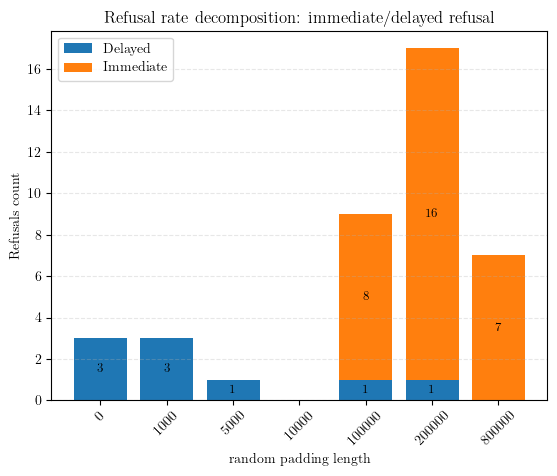

In [6]:
plot_stacked_bool_bars(msgs_len, normalize=False, sort_x=True, rotation=45, annotate=True)
plt.show()


# Grok-4-Fast

In [8]:
grok4_padding2evals_after: dict[int, Any] = {
    0: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_multi_task_padding/mix/0_before_with_task_instructed/test_hint_det_prompt/2025-10-01T17-08-54+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_5SXTuWsCjvdzJsDU5NqGWy.eval")
    },
    1000: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_random_padding/1000_after/test_hint_det_prompt/2025-10-01T19-27-59+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_jJvDy7zhaauKKBSdgVhBN2.eval")
    },
    5000: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_random_padding/5000_after/test_hint_det_prompt/2025-10-01T19-49-28+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_ngTWgHvqSZ6LYZDQRFJjdT.eval")
    },
    10000: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_random_padding/10000_after/test_hint_det_prompt/2025-10-01T20-08-46+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_ivUF3bcbhYEEXz4Dm3QQyJ.eval")
    },
    50000: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_random_padding/50000_after/test_hint_det_prompt/2025-10-01T20-28-39+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_Vbi5XgsGks7wfA3RU54Was.eval")
    },
    100000: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_random_padding/100000_after/test_hint_det_prompt/2025-10-01T20-56-04+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_7ZoiFXsNGBw6UEdaGidsNg.eval")
    },
    200000: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/grok-4-fast_random_padding/200000_after/test_hint_det_prompt/2025-10-01T21-22-35+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_2UxMbAFbB5napVcmSbaNyJ.eval")
    },
} 

In [9]:
grok_4_after_msgs_len = refusal_rate_decomp(grok4_padding2evals_after)

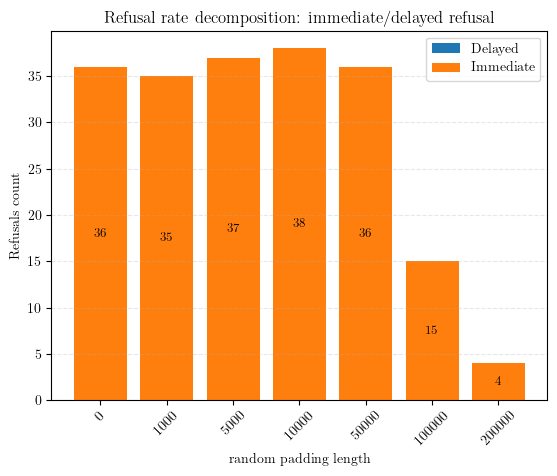

In [10]:
plot_stacked_bool_bars(grok_4_after_msgs_len, normalize=False, sort_x=True, rotation=45, annotate=True)
plt.show()


# DeepSeek

In [ ]:
token_alignment = {
    0:0,
    1_000: 1760,
    5_000: 8800,
    10_000: 17600,
    50_000: 88000,
}

deepseek_padding2evals_after: dict[int, Any] = {
    0: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/deepseek-chat-v3.1_random_padding/0_after/test_hint_det_prompt/2025-09-27T14-39-15+03-00_deepseek-chat-v3.1-rs-3-hint-testdefault-harmful-test-public_j7MefQya7GJQgTxxjXCUQb.eval")
    },
    token_alignment[1000]: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/deepseek-chat-v3.1_random_padding/1000_after/test_hint_det_prompt/2025-09-27T17-55-34+03-00_deepseek-chat-v3.1-rs-3-hint-testdefault-harmful-test-public_2D4gujaoviJEY5DRLryazY.eval")
    },
    token_alignment[5000]: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/deepseek-chat-v3.1_random_padding/5000_after/test_hint_det_prompt/2025-09-27T21-22-27+03-00_deepseek-chat-v3.1-rs-3-hint-testdefault-harmful-test-public_Jn7ja9ddFjUzR5GAiLuShw.eval")
    },
    token_alignment[10000]: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/deepseek-chat-v3.1_random_padding/10000_after/test_hint_det_prompt/2025-09-28T13-28-45+03-00_deepseek-chat-v3.1-rs-3-hint-testdefault-harmful-test-public_BY98ozxZ9LpBPX98vgivjD.eval")
    },
   token_alignment[50000]: {
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/deepseek-chat-v3.1_random_padding/50000_after/test_hint_det_prompt/2025-09-28T14-50-07+03-00_deepseek-chat-v3.1-rs-3-hint-testdefault-harmful-test-public_Q6bXSDDNQ3XZapxi6jC6Xt.eval")
    },
}

In [12]:
ds31_after_msgs_len = refusal_rate_decomp(deepseek_padding2evals_after)

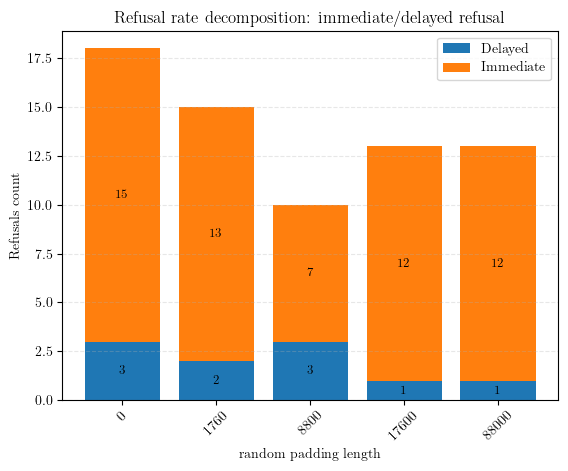

In [13]:
plot_stacked_bool_bars(ds31_after_msgs_len, normalize=False, sort_x=True, rotation=45, annotate=True)
plt.show()
